# Will This Visitor Buy? Real-Time Purchase Intent
**NextGen Institute · Machine Learning Final Project · Anas Refaat**

Most visitors to an online store leave without buying. This project predicts, from one browsing session, whether the visitor will make a purchase, and turns that probability into a real-time action: **no action**, **show a coupon** or **open a chat**.

**Contents**
1. Problem framing
2. Data understanding
3. Exploratory data analysis
4. Preprocessing pipeline
5. Baseline and models
6. Tuning and cross-validation
7. Test-set evaluation and error analysis
8. Business insight: actions, campaign simulation, limitations
9. Saving the pipeline for the web app

## 1 · Problem framing

| | |
|---|---|
| **Who has the problem** | An online retailer. About 85% of sessions end without a purchase. |
| **Decision the model supports** | While a visitor is browsing, decide whether to do nothing, show a discount coupon, or offer live chat. |
| **Target** | `Revenue`: did the session end in a purchase (True / False)? |
| **Main metric** | **ROC-AUC** to rank sessions by purchase intent (the app acts on a ranking), plus **PR-AUC**, because buyers are only ~15% of sessions and accuracy would be misleading. |
| **Operating metrics** | Precision and recall of the "will buy" class at the chosen threshold. Giving coupons to people who would buy anyway wastes margin (precision), and missing hesitant buyers loses sales (recall). |

A model that always says "no purchase" would already be ~85% accurate, so accuracy is not used to choose the model.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from scipy.stats import loguniform, randint
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             average_precision_score, classification_report, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_validate, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))
from features import (CATEGORICAL_COLS, ENGINEERED_COLS, NUMERIC_COLS, RAW_COLS,
                      SessionFeatures, log1p_nonneg)

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
results = {}  # every number quoted in the text is stored here
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 2 · Data understanding

**Source:** [Online Shoppers Purchasing Intention Dataset](https://archive.ics.uci.edu/dataset/468), UCI Machine Learning Repository (Sakar et al., 2018). Each row is one session on a real e-commerce site over one year. The sessions belong to different users, so one user cannot bias the data.

If `data/online_shoppers_intention.csv` is missing, the next cell downloads it from UCI.

In [2]:
DATA_PATH = ROOT / "data" / "online_shoppers_intention.csv"
if not DATA_PATH.exists():
    import io, urllib.request, zipfile
    url = "https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip"
    with urllib.request.urlopen(url) as r:
        zipfile.ZipFile(io.BytesIO(r.read())).extract("online_shoppers_intention.csv", DATA_PATH.parent)

df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


**Column dictionary**

| Column | Meaning |
|---|---|
| `Administrative`, `Informational`, `ProductRelated` | Number of pages of each type visited in the session |
| `*_Duration` | Seconds spent on each page type |
| `BounceRates` | Average bounce rate (Google Analytics) of the pages visited |
| `ExitRates` | Average exit rate of the pages visited |
| `PageValues` | Average value of the pages visited before a transaction (Google Analytics) |
| `SpecialDay` | Closeness of the visit to a special day such as Mother's Day (0 to 1) |
| `Month`, `Weekend` | When the session happened |
| `OperatingSystems`, `Browser`, `Region`, `TrafficType` | Coded technical and marketing attributes |
| `VisitorType` | Returning, new or other visitor |
| `Revenue` | **Target**: the session ended in a purchase |

In [3]:
info = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "unique": df.nunique()})
display(info)

n_dup = int(df.duplicated().sum())
balance = df["Revenue"].value_counts(normalize=True)
results.update(rows=len(df), cols=df.shape[1], n_dup=n_dup, buy_rate=round(100 * balance[True], 1))
print(f"Duplicated rows: {n_dup}")
print(f"Purchase rate: {results['buy_rate']}%")

,dtype,missing,unique
Administrative,int64,0,27
Administrative_Duration,float64,0,3335
Informational,int64,0,17
Informational_Duration,float64,0,1258
ProductRelated,int64,0,311
ProductRelated_Duration,float64,0,9551
BounceRates,float64,0,1872
ExitRates,float64,0,4777
PageValues,float64,0,2704
SpecialDay,float64,0,6


Duplicated rows: 125
Purchase rate: 15.5%


**Observations**
- 12,330 sessions, 18 columns, **no missing values**.
- 125 rows are exact duplicates. They are mostly very short sessions (1 page, bounce rate 0.2) that look identical by nature, so they are kept: dropping them would make the data less like real traffic.
- **Class imbalance:** only **15.5%** of sessions end in a purchase.
- `OperatingSystems`, `Browser`, `Region` and `TrafficType` are stored as numbers but are really category codes, so they are one-hot encoded and not treated as quantities.

## 3 · Exploratory data analysis
### 3.1 Univariate

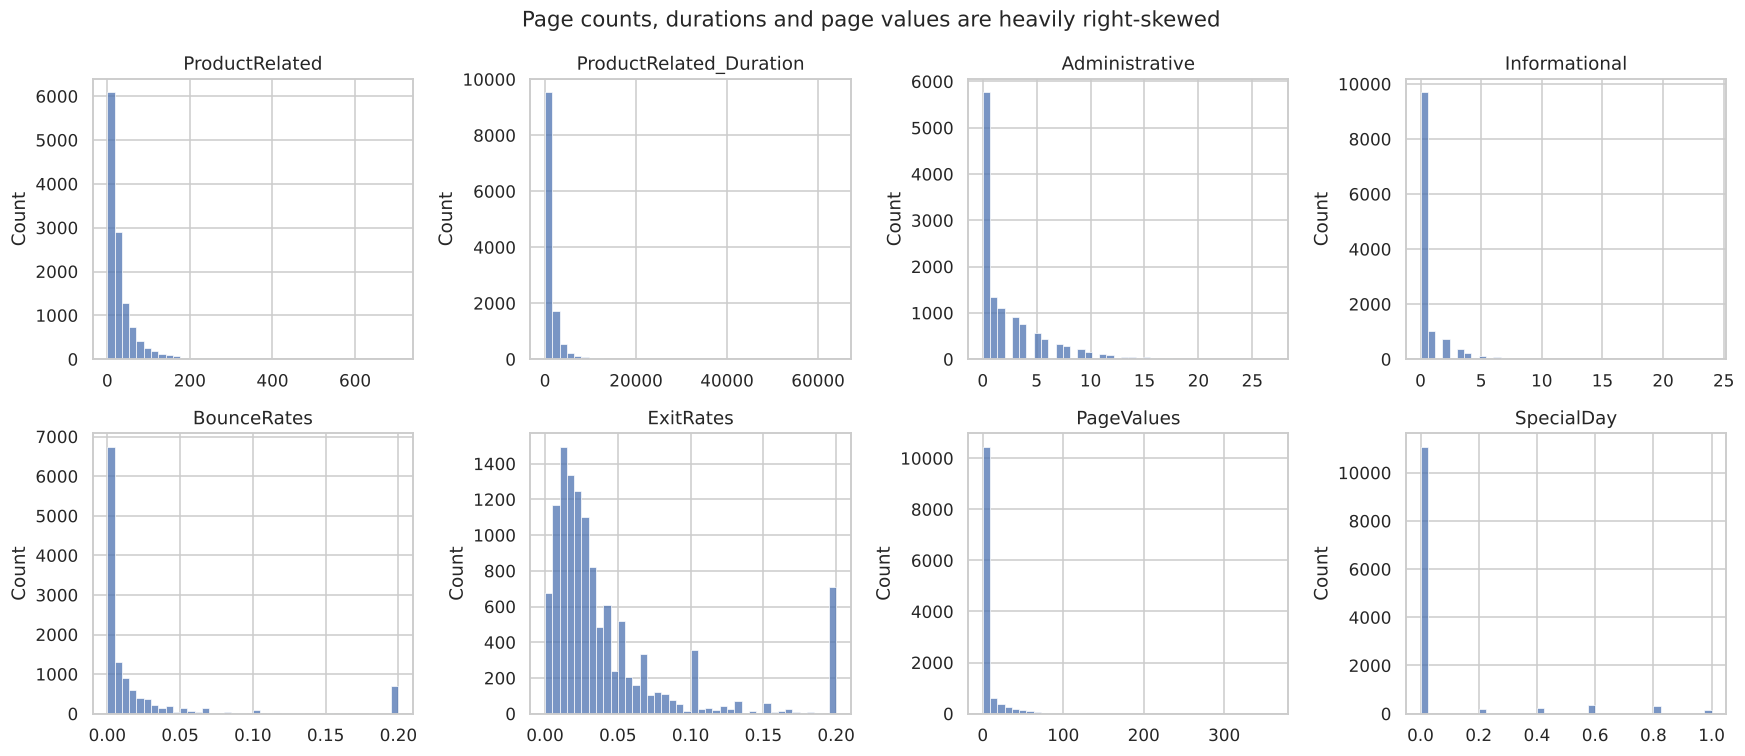

Sessions with PageValues = 0: 77.9%


In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
cols = ["ProductRelated", "ProductRelated_Duration", "Administrative", "Informational",
        "BounceRates", "ExitRates", "PageValues", "SpecialDay"]
for ax, c in zip(axes.ravel(), cols):
    sns.histplot(df[c], bins=40, ax=ax, color="#4C72B0")
    ax.set_title(c)
    ax.set_xlabel("")
fig.suptitle("Page counts, durations and page values are heavily right-skewed", fontsize=14)
plt.tight_layout()
plt.show()

results["pv_zero_pct"] = round(100 * (df["PageValues"] == 0).mean(), 1)
print(f"Sessions with PageValues = 0: {results['pv_zero_pct']}%")

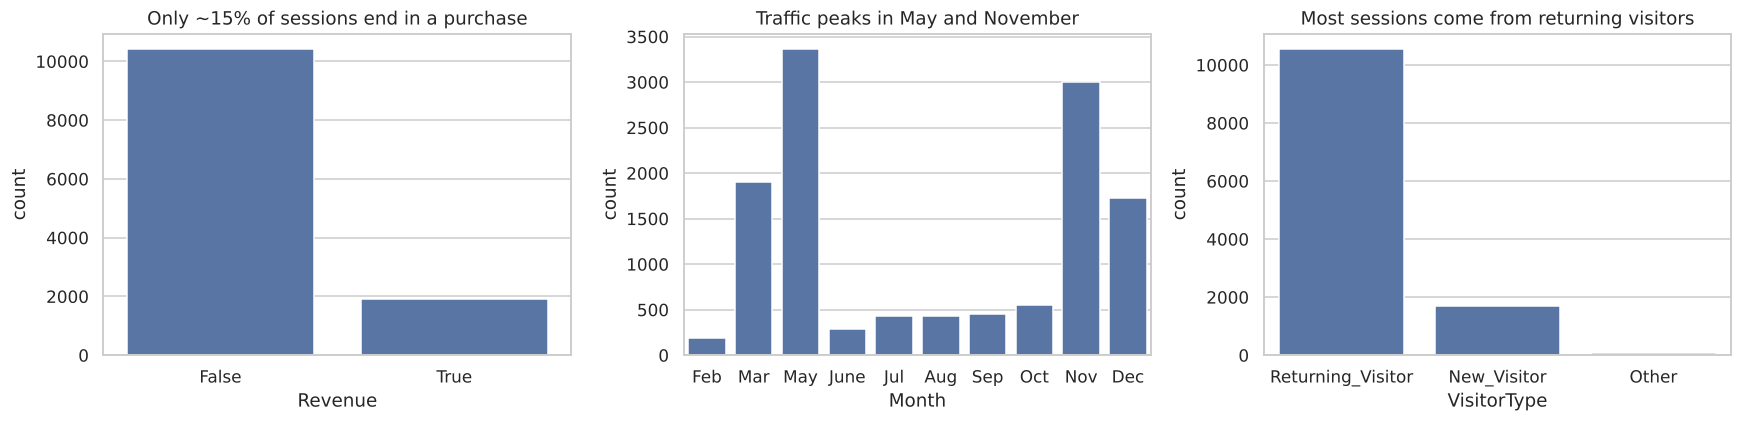

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x="Revenue", data=df, ax=axes[0])
axes[0].set_title("Only ~15% of sessions end in a purchase")
order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
sns.countplot(x="Month", data=df, order=order, ax=axes[1], color="#4C72B0")
axes[1].set_title("Traffic peaks in May and November")
sns.countplot(x="VisitorType", data=df, ax=axes[2], color="#4C72B0")
axes[2].set_title("Most sessions come from returning visitors")
plt.tight_layout()
plt.show()

### 3.2 Bivariate: what separates buyers from non-buyers?

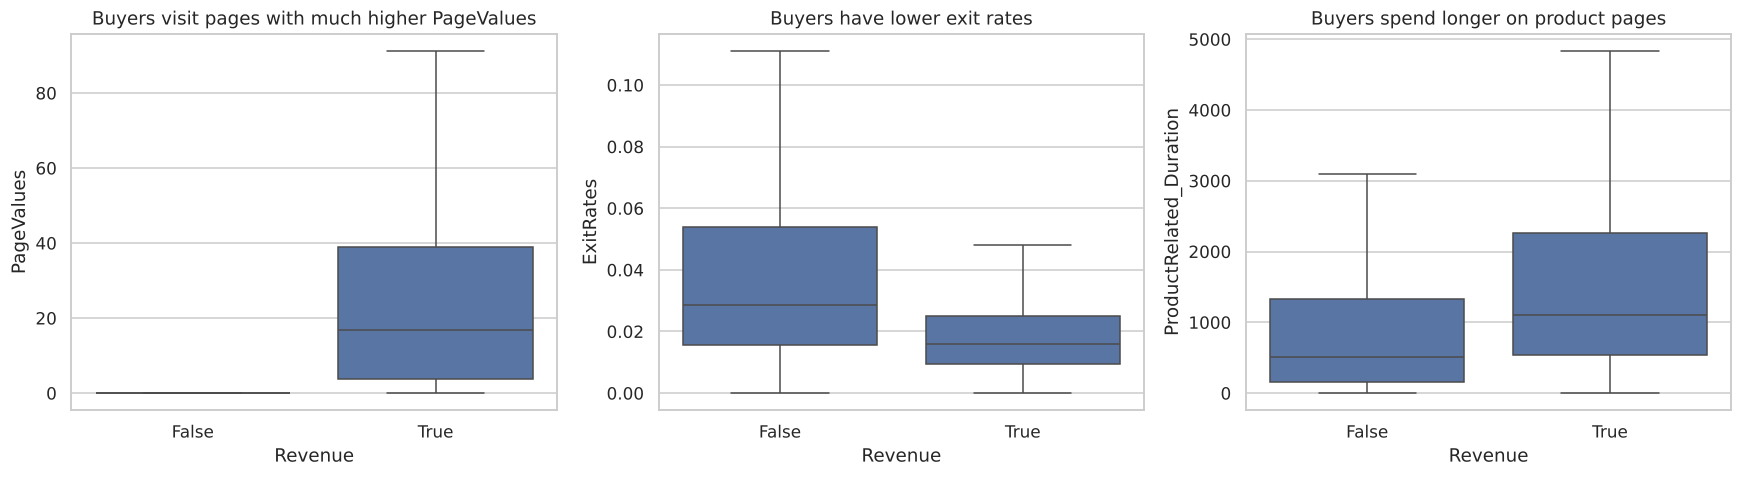

Conversion when PageValues = 0: 3.9%  |  when > 0: 56.3%


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(x="Revenue", y="PageValues", data=df, ax=axes[0], showfliers=False)
axes[0].set_title("Buyers visit pages with much higher PageValues")
sns.boxplot(x="Revenue", y="ExitRates", data=df, ax=axes[1], showfliers=False)
axes[1].set_title("Buyers have lower exit rates")
sns.boxplot(x="Revenue", y="ProductRelated_Duration", data=df, ax=axes[2], showfliers=False)
axes[2].set_title("Buyers spend longer on product pages")
plt.tight_layout()
plt.show()

conv_pv = df.groupby(df["PageValues"] > 0)["Revenue"].mean() * 100
results["conv_pv0"] = round(conv_pv[False], 1)
results["conv_pv1"] = round(conv_pv[True], 1)
print(f"Conversion when PageValues = 0: {results['conv_pv0']}%  |  when > 0: {results['conv_pv1']}%")

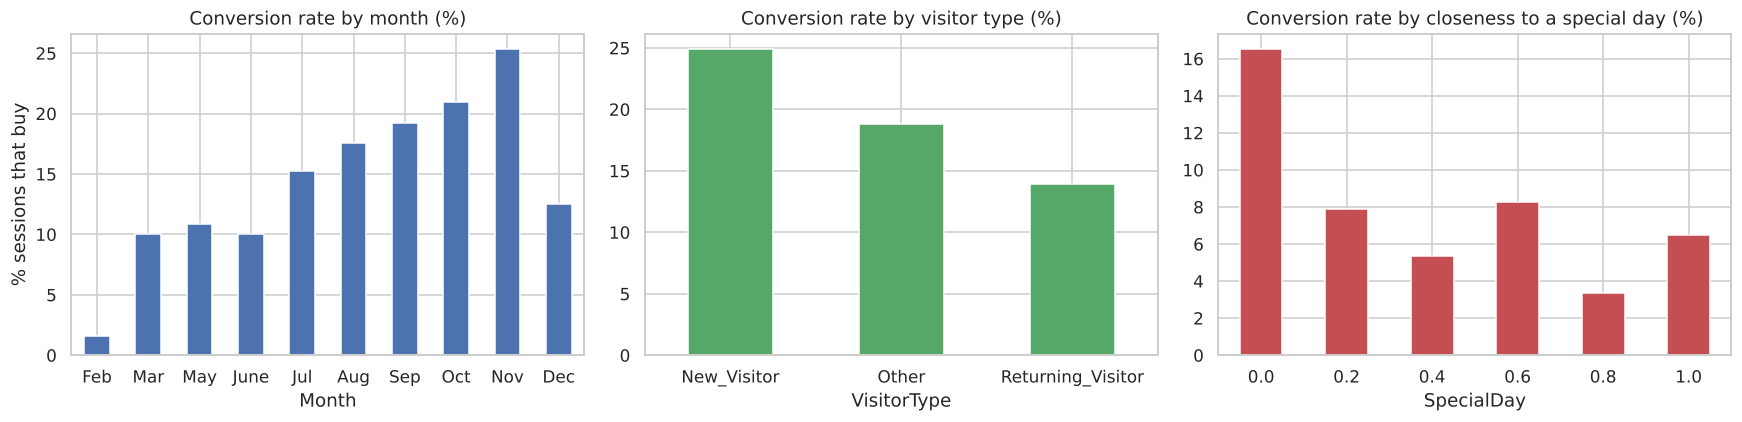

{'rows': 12330, 'cols': 18, 'n_dup': 125, 'buy_rate': np.float64(15.5), 'pv_zero_pct': np.float64(77.9), 'conv_pv0': np.float64(3.9), 'conv_pv1': np.float64(56.3), 'conv_nov': np.float64(25.4), 'conv_feb': np.float64(1.6), 'conv_new': np.float64(24.9), 'conv_ret': np.float64(13.9), 'conv_sd0': np.float64(16.5)}


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
m = df.groupby("Month")["Revenue"].mean().reindex(order) * 100
m.plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Conversion rate by month (%)")
axes[0].set_ylabel("% sessions that buy")
v = df.groupby("VisitorType")["Revenue"].mean() * 100
v.plot(kind="bar", ax=axes[1], color="#55A868")
axes[1].set_title("Conversion rate by visitor type (%)")
s = df.groupby("SpecialDay")["Revenue"].mean() * 100
s.plot(kind="bar", ax=axes[2], color="#C44E52")
axes[2].set_title("Conversion rate by closeness to a special day (%)")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

results["conv_nov"] = round(m["Nov"], 1)
results["conv_feb"] = round(m["Feb"], 1)
results["conv_new"] = round(v["New_Visitor"], 1)
results["conv_ret"] = round(v["Returning_Visitor"], 1)
results["conv_sd0"] = round(s.loc[0.0], 1)
print(results)

### 3.3 Multivariate

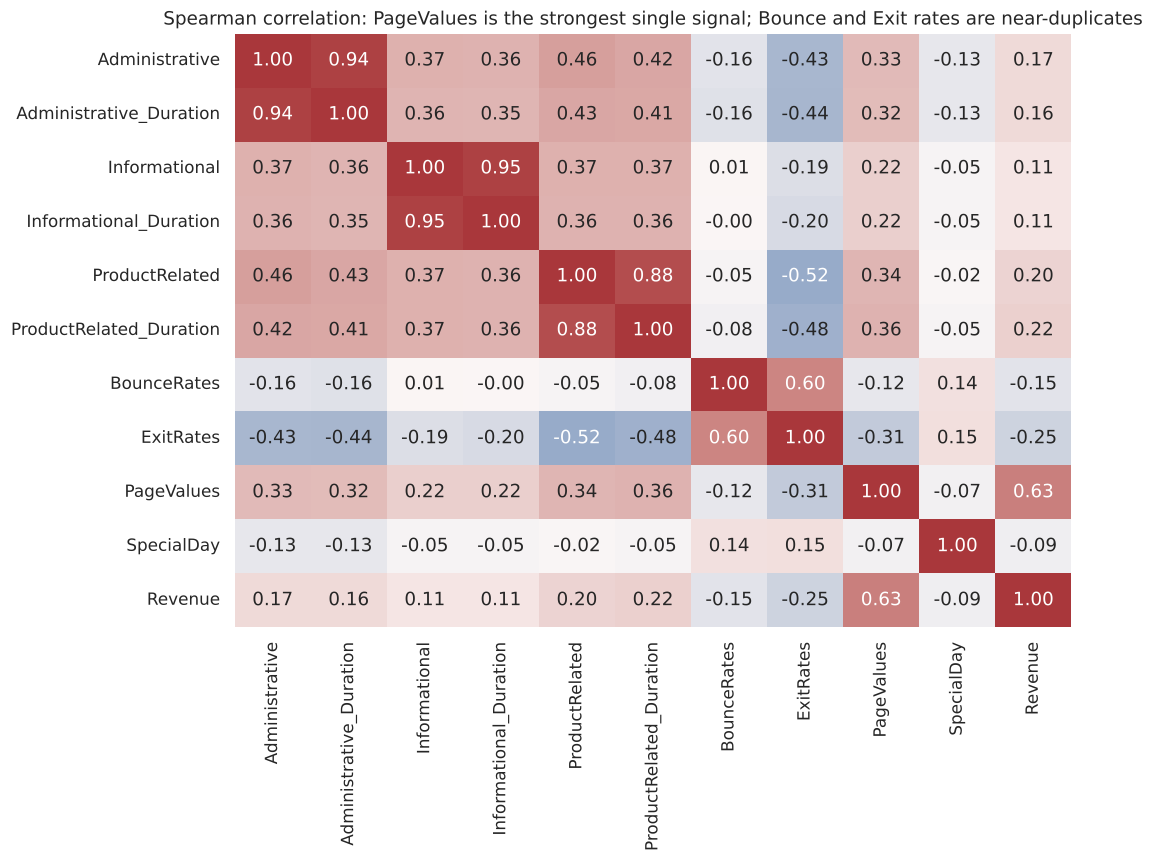

In [8]:
num = df[NUMERIC_COLS + ["Revenue"]].astype(float)
plt.figure(figsize=(10, 8))
sns.heatmap(num.corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", center=0, cbar=False)
plt.title("Spearman correlation: PageValues is the strongest single signal; Bounce and Exit rates are near-duplicates")
plt.tight_layout()
plt.show()

corr = num.corr(method="spearman")
results["corr_bounce_exit"] = round(corr.loc["BounceRates", "ExitRates"], 2)
results["corr_pv_rev"] = round(corr.loc["PageValues", "Revenue"], 2)

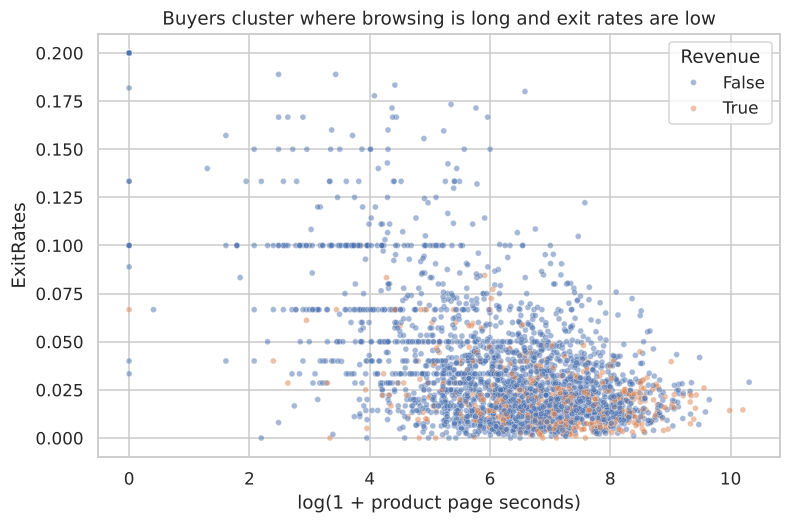

In [9]:
sample = df.sample(3000, random_state=RANDOM_STATE)
plt.figure(figsize=(8, 5))
sns.scatterplot(x=np.log1p(sample["ProductRelated_Duration"]), y=sample["ExitRates"],
                hue=sample["Revenue"], alpha=0.5, s=15)
plt.xlabel("log(1 + product page seconds)")
plt.title("Buyers cluster where browsing is long and exit rates are low")
plt.show()

### EDA insights
1. **PageValues dominates.** Conversion is **56.3%** when the visitor has seen a page with value > 0 and only **3.9%** when they have not (Spearman ρ with the target = 0.63).
2. **Engagement matters.** Buyers spend longer on product pages and have lower exit and bounce rates. Bounce and exit rates are strongly correlated (ρ = 0.6), so they carry overlapping information.
3. **Seasonality.** November converts best (25.4%) and February worst (1.6%). Volume peaks in May but conversion does not, so busy months are not the same as buying months.
4. **New visitors convert more** (24.9%) than returning visitors (13.9%). Many returning visitors seem to be researching rather than buying.
5. **"Special day" proximity does not raise conversion.** Sessions far from a special day (SpecialDay = 0) convert at 16.5%, higher than sessions close to one. This goes against the usual intuition.

**Hypothesis for the model:** PageValues, exit rate, product-page engagement, month and visitor type will be the main drivers. Device and region codes will add little.

## 4 · Preprocessing pipeline

Everything that learns from data lives inside one scikit-learn `Pipeline`, and the data is **split before anything is fitted**, so the test set never influences preprocessing.

- `SessionFeatures`: adds `TotalPages`, `TotalDuration`, `AvgProductDuration` (seconds per product page) and `HasPageValue`, and casts the code columns to strings. It is stateless, so it cannot leak.
- **Numeric:** `log1p` to tame the heavy right skew and outliers (no rows dropped, because long sessions are real behaviour), then `StandardScaler`.
- **Categorical:** `OneHotEncoder` with rare codes (fewer than 20 rows) grouped into "infrequent", so unseen codes in the app do not crash the model.
- No imputation step is needed (no missing values), but the encoder's `handle_unknown` protects the app against unexpected categories.

In [10]:
X = df.drop(columns="Revenue")
y = df["Revenue"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
results.update(n_train=len(X_train), n_test=len(X_test))
print(X_train.shape, X_test.shape, f"train buy rate {y_train.mean():.3f}", f"test buy rate {y_test.mean():.3f}")

num_features = NUMERIC_COLS + ["TotalPages", "TotalDuration", "AvgProductDuration", "HasPageValue", "Weekend"]

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("log", FunctionTransformer(log1p_nonneg)),
                          ("scale", StandardScaler())]), num_features),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                              sparse_output=False), CATEGORICAL_COLS),
    ])

def make_pipeline(model):
    return Pipeline([("features", SessionFeatures()), ("prep", make_preprocessor()), ("model", model)])

make_pipeline(LogisticRegression())

(9864, 17) (2466, 17) train buy rate 0.155 test buy rate 0.155


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

## 5 · Baseline and models

All models are compared with **5-fold stratified cross-validation on the training set only**.
- **Baseline:** `DummyClassifier`, always predicting the majority class "no purchase".
- **Logistic regression:** a linear, interpretable model, with `class_weight="balanced"` for the imbalance.
- **K-nearest neighbours:** distance-based.
- **Decision tree:** non-linear and readable.
- **Random forest:** an ensemble of trees.
- **Histogram gradient boosting:** boosted trees.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1",
           "precision": "precision", "recall": "recall", "accuracy": "accuracy"}

candidates = {
    "Baseline (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "KNN (k=15)": KNeighborsClassifier(n_neighbors=15),
    "Decision tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_STATE),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                            class_weight="balanced_subsample",
                                            random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

rows = []
for name, model in candidates.items():
    scores = cross_validate(make_pipeline(model), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"model": name, **{k: scores[f"test_{k}"].mean() for k in scoring},
                 "roc_auc_std": scores["test_roc_auc"].std()})

cv_table = pd.DataFrame(rows).set_index("model").sort_values("roc_auc", ascending=False).round(3)
display(cv_table)
results["cv_table"] = cv_table.reset_index().to_dict(orient="records")
results["base_acc"] = cv_table.loc["Baseline (majority)", "accuracy"]

,roc_auc,pr_auc,f1,precision,recall,accuracy,roc_auc_std
model,,,,,,,
Gradient boosting,0.932,0.748,0.651,0.720,0.594,0.901,0.005
Random forest,0.932,0.750,0.694,0.643,0.754,0.897,0.004
Logistic regression,0.922,0.672,0.656,0.545,0.826,0.866,0.004
Decision tree,0.909,0.662,0.627,0.496,0.853,0.843,0.007
KNN (k=15),0.907,0.689,0.638,0.690,0.595,0.896,0.006
Baseline (majority),0.500,0.155,0.000,0.000,0.000,0.845,0.000


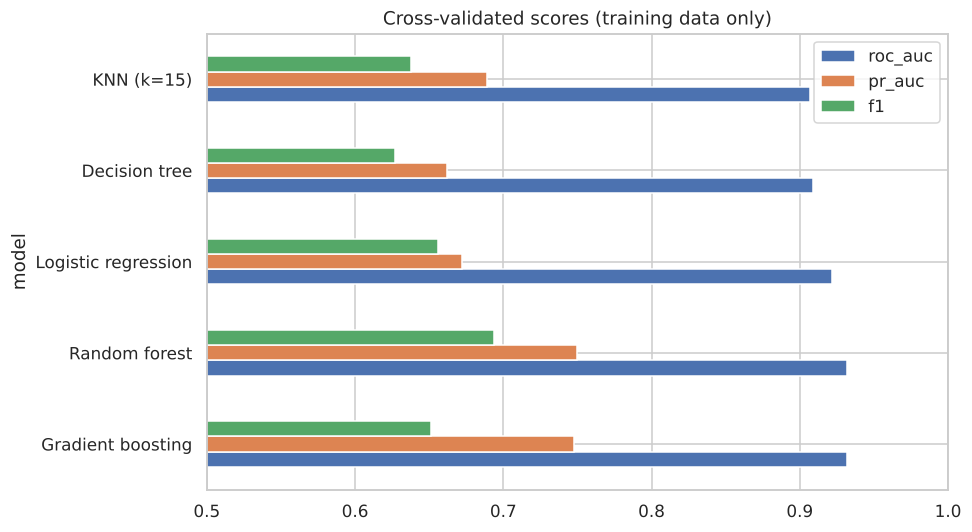

In [12]:
ax = cv_table.drop("Baseline (majority)")[["roc_auc", "pr_auc", "f1"]].plot(kind="barh", figsize=(9, 5))
ax.set_xlim(0.5, 1)
ax.set_title("Cross-validated scores (training data only)")
plt.tight_layout()
plt.show()

**Reading the table:** the baseline reaches **0.845 accuracy** with **zero recall**: it never finds a buyer. This is why accuracy is not the selection metric. The tree ensembles (random forest and gradient boosting) lead on both ROC-AUC and PR-AUC, so both go forward to tuning.

## 6 · Hyperparameter tuning (training data only)

`RandomizedSearchCV` with the same 5 folds, optimising **PR-AUC** (`average_precision`). PR-AUC focuses on how well the rare buyer class is ranked, which is what the coupon and chat decisions depend on.

In [13]:
search_spaces = {
    "Random forest": (
        RandomForestClassifier(class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1),
        {"model__n_estimators": randint(200, 600),
         "model__max_depth": [None, 8, 12, 16, 24],
         "model__min_samples_leaf": randint(1, 15),
         "model__max_features": ["sqrt", "log2", 0.3, 0.5]}),
    "Gradient boosting": (
        HistGradientBoostingClassifier(random_state=RANDOM_STATE),
        {"model__learning_rate": loguniform(0.02, 0.3),
         "model__max_iter": randint(100, 500),
         "model__max_leaf_nodes": randint(8, 48),
         "model__min_samples_leaf": randint(10, 80),
         "model__l2_regularization": loguniform(1e-3, 10),
         "model__class_weight": [None, "balanced"]}),
}

searches = {}
for name, (model, space) in search_spaces.items():
    s = RandomizedSearchCV(make_pipeline(model), space, n_iter=30, scoring="average_precision",
                           cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
    s.fit(X_train, y_train)
    searches[name] = s
    print(f"{name}: best CV PR-AUC = {s.best_score_:.3f}")
    print("   ", {k.replace('model__', ''): (round(v, 4) if isinstance(v, float) else v)
                  for k, v in s.best_params_.items()})

Random forest: best CV PR-AUC = 0.754
    {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 9, 'n_estimators': 543}


Gradient boosting: best CV PR-AUC = 0.759
    {'class_weight': None, 'l2_regularization': np.float64(0.016), 'learning_rate': np.float64(0.0433), 'max_iter': 180, 'max_leaf_nodes': 9, 'min_samples_leaf': 11}


In [14]:
tuned_rows = []
for name, s in searches.items():
    sc = cross_validate(s.best_estimator_, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    tuned_rows.append({"model": f"{name} (tuned)", **{k: sc[f"test_{k}"].mean() for k in scoring}})
tuned_table = pd.DataFrame(tuned_rows).set_index("model").round(3)
display(tuned_table)

best_name = tuned_table["pr_auc"].idxmax()
final_model = searches[best_name.replace(" (tuned)", "")].best_estimator_
results["best_name"] = best_name
results["best_cv_pr_auc"] = tuned_table.loc[best_name, "pr_auc"]
results["best_cv_roc_auc"] = tuned_table.loc[best_name, "roc_auc"]
results["n_models"] = len(candidates) - 1
print("Selected:", best_name)

,roc_auc,pr_auc,f1,precision,recall,accuracy
model,,,,,,
Random forest (tuned),0.934,0.754,0.681,0.595,0.798,0.884
Gradient boosting (tuned),0.935,0.759,0.667,0.731,0.615,0.905


Selected: Gradient boosting (tuned)


### Choosing the decision threshold (still on training data)

The default 0.5 threshold is arbitrary. Out-of-fold probabilities from cross-validation on the training set are used to pick the threshold that **maximises F1** for the buyer class. This balances wasted coupons (false positives) against missed buyers (false negatives). The test set is still untouched.

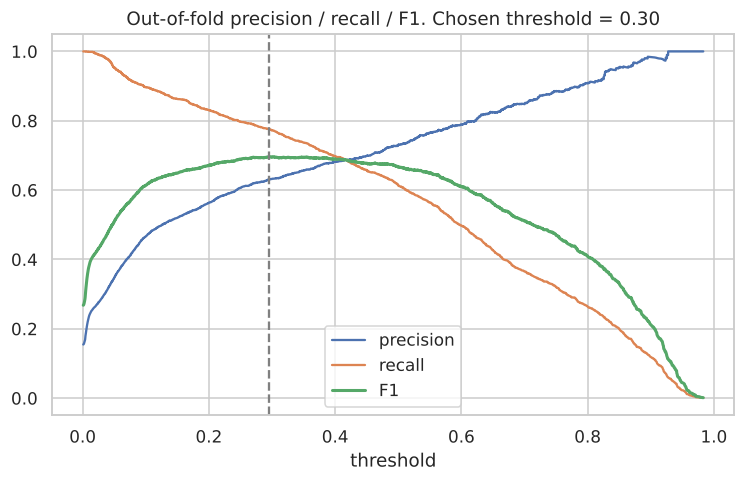

In [15]:
oof = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_t = float(thr[np.argmax(f1s)])
results["threshold"] = round(best_t, 2)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thr, prec[:-1], label="precision")
ax.plot(thr, rec[:-1], label="recall")
ax.plot(thr, f1s, label="F1", lw=2)
ax.axvline(best_t, color="grey", ls="--")
ax.set_xlabel("threshold")
ax.set_title(f"Out-of-fold precision / recall / F1. Chosen threshold = {best_t:.2f}")
ax.legend()
plt.show()

## 7 · Final evaluation on the untouched test set

The selected model (Gradient boosting (tuned)) is evaluated once on the 2,466 held-out sessions.

In [16]:
proba_test = final_model.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= best_t).astype(int)
base_proba = np.full(len(y_test), y_train.mean())

test_metrics = {
    "ROC-AUC": roc_auc_score(y_test, proba_test),
    "PR-AUC": average_precision_score(y_test, proba_test),
    "F1": f1_score(y_test, pred_test),
    "Precision": precision_score(y_test, pred_test),
    "Recall": recall_score(y_test, pred_test),
    "Accuracy": (pred_test == y_test).mean(),
}
baseline_metrics = {"ROC-AUC": 0.5, "PR-AUC": average_precision_score(y_test, base_proba),
                    "F1": 0.0, "Precision": 0.0, "Recall": 0.0, "Accuracy": 1 - y_test.mean()}
test_table = pd.DataFrame({"Baseline (majority)": baseline_metrics, best_name: test_metrics}).round(3)
display(test_table)

for k, v in test_metrics.items():
    results["test_" + k.lower().replace("-", "_")] = round(v, 3)
results["base_test_acc"] = round(baseline_metrics["Accuracy"], 3)
results["base_test_prauc"] = round(baseline_metrics["PR-AUC"], 3)
print(classification_report(y_test, pred_test, target_names=["no purchase", "purchase"], digits=3))

,Baseline (majority),Gradient boosting (tuned)
ROC-AUC,0.500,0.932
PR-AUC,0.155,0.748
F1,0.000,0.671
Precision,0.000,0.619
Recall,0.000,0.733
Accuracy,0.845,0.889


              precision    recall  f1-score   support

 no purchase      0.949     0.917     0.933      2084
    purchase      0.619     0.733     0.671       382

    accuracy                          0.889      2466
   macro avg      0.784     0.825     0.802      2466
weighted avg      0.898     0.889     0.893      2466



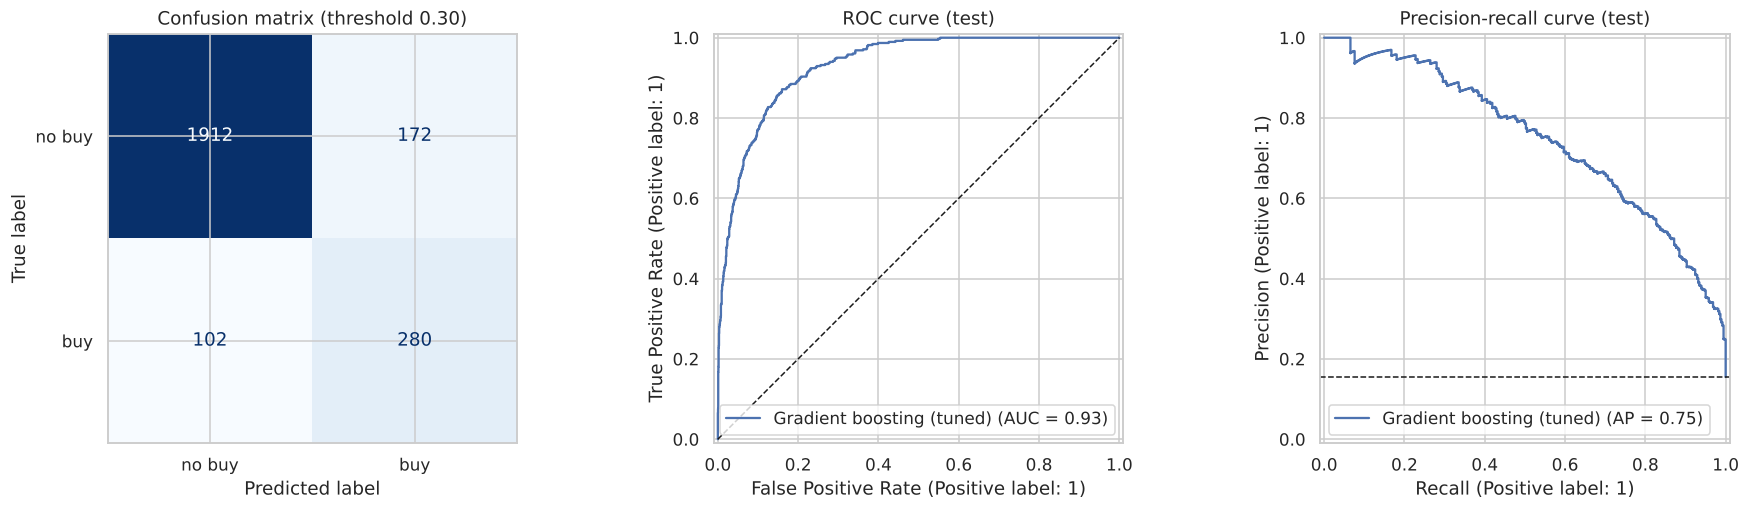

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["no buy", "buy"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion matrix (threshold {best_t:.2f})")
RocCurveDisplay.from_predictions(y_test, proba_test, ax=axes[1], name=best_name)
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("ROC curve (test)")
PrecisionRecallDisplay.from_predictions(y_test, proba_test, ax=axes[2], name=best_name)
axes[2].axhline(y_test.mean(), color="k", ls="--", lw=1, label="baseline")
axes[2].set_title("Precision-recall curve (test)")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()
results.update(tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp), n_buyers_test=int(y_test.sum()))

### Error analysis: what do the mistakes look like?

In [18]:
err = X_test.copy()
err["actual"] = y_test.values
err["proba"] = proba_test
err["outcome"] = np.select(
    [(err.actual == 1) & (pred_test == 1), (err.actual == 0) & (pred_test == 1),
     (err.actual == 1) & (pred_test == 0)],
    ["TP", "FP", "FN"], default="TN")

summary = err.groupby("outcome").agg(
    sessions=("proba", "size"), mean_proba=("proba", "mean"),
    pagevalue_zero_pct=("PageValues", lambda s: 100 * (s == 0).mean()),
    product_pages=("ProductRelated", "median"), exit_rate=("ExitRates", "median"),
    new_visitor_pct=("VisitorType", lambda s: 100 * (s == "New_Visitor").mean()),
).round(2)
display(summary)
results["fn_pv0_pct"] = round(summary.loc["FN", "pagevalue_zero_pct"], 0)
results["fp_pv0_pct"] = round(summary.loc["FP", "pagevalue_zero_pct"], 0)

,sessions,mean_proba,pagevalue_zero_pct,product_pages,exit_rate,new_visitor_pct
outcome,,,,,,
FN,102,0.14,80.39,28.0,0.02,20.59
FP,172,0.51,2.91,36.0,0.02,5.81
TN,1912,0.04,96.23,15.0,0.03,12.97
TP,280,0.68,0.71,29.0,0.01,24.29


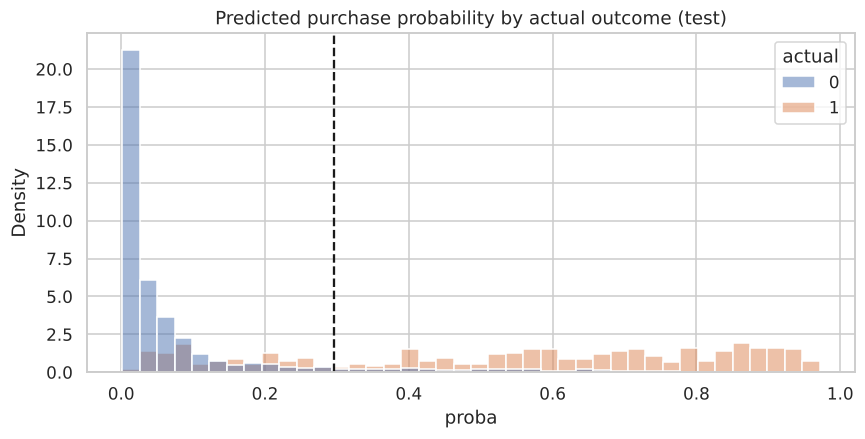

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=err, x="proba", hue="actual", bins=40, stat="density", common_norm=False, ax=ax)
ax.axvline(best_t, color="k", ls="--")
ax.set_title("Predicted purchase probability by actual outcome (test)")
plt.show()

**Error analysis**
- Out of 382 real buyers in the test set, the model finds **280** (recall 0.733) and misses **102**. Of all sessions it flags as buyers, **0.619** are correct.
- **80% of missed buyers had PageValues = 0.** They bought without first visiting the pages that usually lead to a purchase (for example a quick direct checkout), so there is almost no signal before the purchase. This is the model's main blind spot.
- False alarms are the opposite: sessions with a positive PageValue and long product browsing that still left without buying. These hesitant visitors are exactly who a coupon is meant for, so many false positives are still good coupon targets.

### Which features drive the prediction?

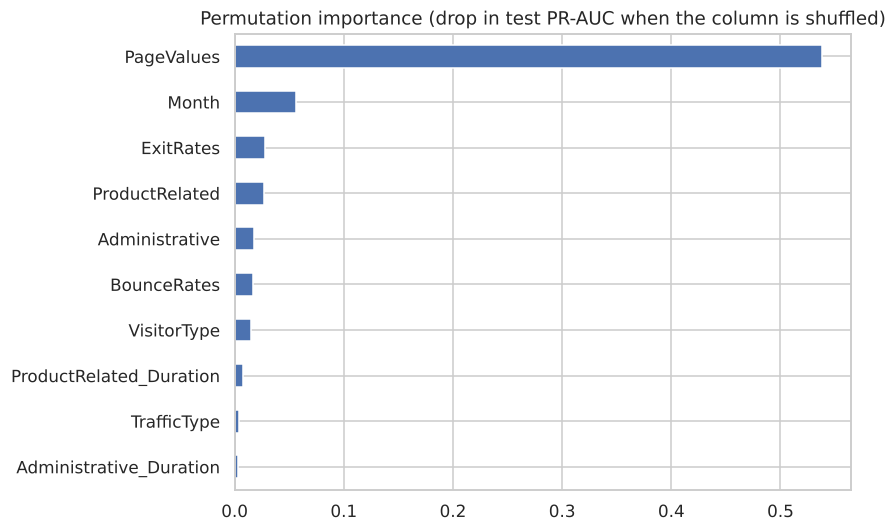

['PageValues', 'Month', 'ExitRates', 'ProductRelated']


In [20]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(final_model, X_test, y_test, scoring="average_precision",
                            n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp.tail(10).plot(kind="barh", figsize=(8, 5), color="#4C72B0")
plt.title("Permutation importance (drop in test PR-AUC when the column is shuffled)")
plt.tight_layout()
plt.show()
results["top_features"] = list(imp.sort_values(ascending=False).index[:4])
print(results["top_features"])

## 8 · Business insight

### From probability to action
The app turns each session's probability into one of three actions. The cut-offs come from **out-of-fold training predictions** (not the test set):

| Probability band | Action | Why |
|---|---|---|
| ≥ high cut-off | **No action** | Very likely to buy anyway, so a coupon would only give away margin |
| middle band | **Show coupon** | Hesitant but interested: the most persuadable group |
| < low cut-off | **Show chat** | Low intent: a cheap chat can answer questions without spending on discounts |

In [21]:
low_cut = round(best_t / 2, 2)
high_cut = round(float(np.quantile(oof[y_train == 1], 0.5)), 2)
high_cut = max(high_cut, round(best_t + 0.15, 2))
bands = pd.cut(proba_test, [-0.01, low_cut, high_cut, 1.01], labels=["Show chat", "Show coupon", "No action"])
band_table = pd.DataFrame({"band": bands, "buy": y_test.values}).groupby("band", observed=False).agg(
    sessions=("buy", "size"), actual_conversion_pct=("buy", lambda s: round(100 * s.mean(), 1)))
display(band_table)
results.update(low_cut=low_cut, high_cut=high_cut,
               conv_noaction=band_table.loc["No action", "actual_conversion_pct"],
               conv_coupon=band_table.loc["Show coupon", "actual_conversion_pct"],
               conv_chat=band_table.loc["Show chat", "actual_conversion_pct"],
               n_coupon=int(band_table.loc["Show coupon", "sessions"]))

,sessions,actual_conversion_pct
band,,
Show chat,1836,3.1
Show coupon,405,35.8
No action,225,80.4


On the test set the bands behave as intended. Sessions in **"No action"** actually converted at **80.4%**, the **coupon band** at **35.8%**, and the **chat band** at only **3.1%**.

### Campaign simulation (stretch goal)
**Question:** if the shop gives a coupon to **10% of visitors**, how many extra sales could it get by choosing them with the model instead of at random?

The data does not say how a coupon changes behaviour, so the answer depends on an **assumed uplift**. Two scenarios are compared, and both assumptions are stated openly:
- **Scenario A, uniform uplift:** a coupon converts 10% of *any* non-buyer who receives it.
- **Scenario B, intent-dependent uplift:** a coupon converts 20% of interested non-buyers (coupon band) but only 2% of low-intent non-buyers (chat band). This is the usual marketing belief that people who already showed interest are easier to persuade.

In both scenarios a coupon does nothing for someone who would buy anyway; that coupon is wasted margin.

In [22]:
k = int(0.10 * len(y_test))
test_df = pd.DataFrame({"proba": proba_test, "buy": y_test.values})
test_df["band"] = pd.cut(test_df.proba, [-0.01, low_cut, high_cut, 1.01],
                         labels=["Show chat", "Show coupon", "No action"])

# Model targeting: skip likely buyers ("No action" band), take the highest-intent sessions below it
targeted = test_df[test_df.proba < high_cut].sort_values("proba", ascending=False).head(k)
rng = np.random.default_rng(RANDOM_STATE)
random_pick = test_df.iloc[rng.choice(len(test_df), k, replace=False)]

def extra_sales(group, scenario):
    non_buyers = group[group.buy == 0]
    if scenario == "A":
        return 0.10 * len(non_buyers)
    uplift = np.where(non_buyers.band == "Show chat", 0.02, 0.20)
    return float(uplift.sum())

sim = pd.DataFrame({
    "coupons sent": [k, k],
    "coupons wasted on buyers": [int(targeted.buy.sum()), int(random_pick.buy.sum())],
    "extra sales, scenario A (uniform 10%)": [round(extra_sales(targeted, "A"), 1), round(extra_sales(random_pick, "A"), 1)],
    "extra sales, scenario B (intent-dependent)": [round(extra_sales(targeted, "B"), 1), round(extra_sales(random_pick, "B"), 1)],
}, index=["Model-targeted", "Random"])
display(sim)
results.update(k_coupons=k,
               wasted_model=int(sim.iloc[0, 1]), wasted_random=int(sim.iloc[1, 1]),
               extraA_model=sim.iloc[0, 2], extraA_random=sim.iloc[1, 2],
               extraB_model=sim.iloc[0, 3], extraB_random=sim.iloc[1, 3])

,coupons sent,coupons wasted on buyers,"extra sales, scenario A (uniform 10%)","extra sales, scenario B (intent-dependent)"
Model-targeted,246,103,14.3,28.6
Random,246,41,20.5,8.8


**What the simulation shows, honestly:**
- **Scenario A (uniform uplift):** random targeting wins (20.5 vs 14.3 extra sales). The model sends more coupons to people who were going to buy anyway (103 vs 41), because the visitors just below the "buy anyway" band still convert often. If every non-buyer were equally persuadable, there would be no reason to target at all.
- **Scenario B (intent-dependent uplift):** model targeting wins clearly (28.6 vs 8.8 extra sales), because it puts the coupons in front of interested visitors instead of people who were never going to buy.

So **the business case depends on whether interested visitors respond more to coupons**, and this data cannot answer that. The right next step is an **A/B test in the coupon band**: give half the coupon, measure the uplift and coupon cost, and only then scale.

### Recommendations
1. **Deploy as a ranking, not a yes/no.** Use the three bands above, and change the cut-offs as the marketing budget changes.
2. **Run an A/B test** on the coupon band to measure true uplift and coupon cost before scaling.
3. **Invest in tracking.** PageValues is the strongest signal; better page-level tracking (cart and checkout events) would close the model's main blind spot (buyers with PageValues = 0).
4. **Time campaigns to November.** It has the highest natural conversion; February needs stronger incentives.

### Limitations
- **PageValues is computed by Google Analytics from historical transactions.** It is available during a session, but its definition depends on the site's analytics setup, and the model relies on it heavily.
- One shop, one year (no January or April data), so it may not generalise to other stores or seasons without retraining.
- The campaign numbers depend on an assumed uplift and are not measured results.
- The predicted probabilities rank sessions well but are not perfectly calibrated, so treat them as scores rather than exact chances.

## 9 · Save the pipeline for the web app

In [23]:
model_dir = ROOT / "model"
model_dir.mkdir(exist_ok=True)
joblib.dump(final_model, model_dir / "purchase_intent_pipeline.joblib", compress=3)

meta = {
    "model": best_name,
    "threshold": round(best_t, 3),
    "low_cut": low_cut,
    "high_cut": high_cut,
    "test_metrics": {k: round(v, 3) for k, v in test_metrics.items()},
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "sklearn_version": sklearn.__version__,
    "feature_medians": X_train[NUMERIC_COLS].median().round(4).to_dict(),
}
(model_dir / "metadata.json").write_text(json.dumps(meta, indent=2))
(ROOT / "notebooks" / "results.json").write_text(json.dumps(results, indent=2, default=float))
print(json.dumps(meta, indent=2)[:600])

{
  "model": "Gradient boosting (tuned)",
  "threshold": 0.296,
  "low_cut": 0.15,
  "high_cut": 0.6,
  "test_metrics": {
    "ROC-AUC": 0.932,
    "PR-AUC": 0.748,
    "F1": 0.671,
    "Precision": 0.619,
    "Recall": 0.733,
    "Accuracy": 0.889
  },
  "train_rows": 9864,
  "test_rows": 2466,
  "sklearn_version": "1.9.1",
  "feature_medians": {
    "Administrative": 1.0,
    "Administrative_Duration": 8.0,
    "Informational": 0.0,
    "Informational_Duration": 0.0,
    "ProductRelated": 18.0,
    "ProductRelated_Duration": 600.5367,
    "BounceRates": 0.0031,
    "ExitRates": 0.0252,
    "


### Final summary
- **Data:** 12,330 real e-commerce sessions; only 15.5% end in a purchase.
- **Models:** a majority baseline plus 5 algorithms, compared with 5-fold CV; the best two were tuned with randomized search on the training data only.
- **Selected model:** Gradient boosting (tuned). **Test ROC-AUC 0.932, PR-AUC 0.748** (baseline PR-AUC 0.155). At threshold 0.3 it finds **280 of 382 buyers (recall 0.733)** with precision 0.619.
- **Product:** a Streamlit app that turns a session into *no action / coupon / chat* in real time.